In [5]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)


**Задание 1**

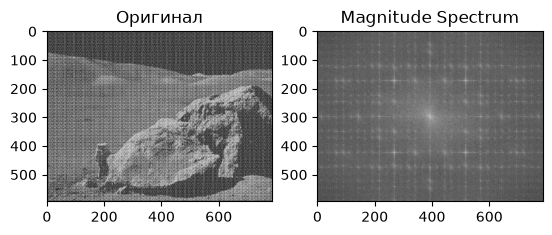

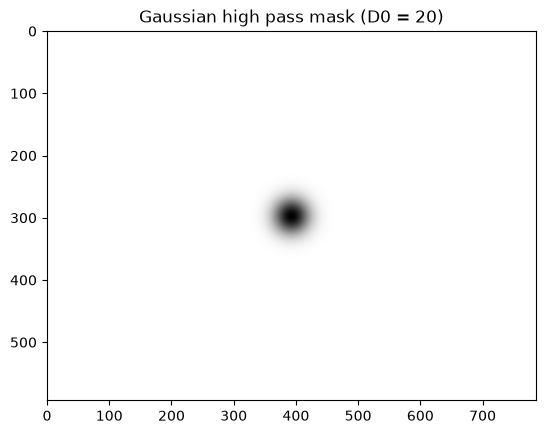

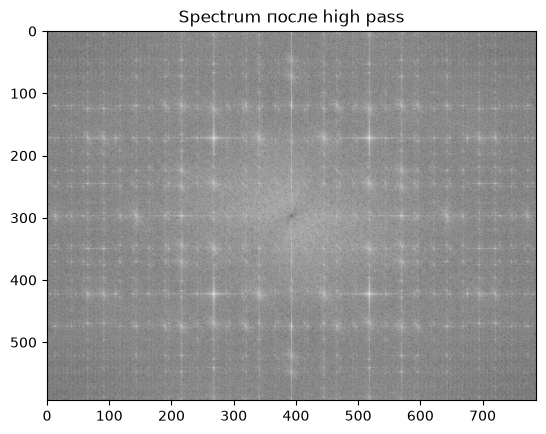

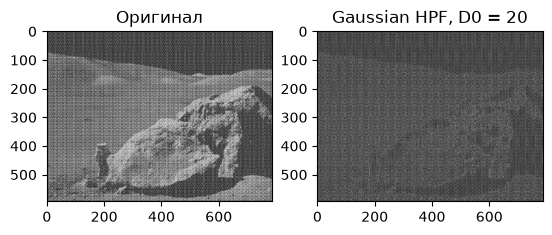

In [6]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Оригинал')
plt.subplot(122), plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Magnitude Spectrum')
plt.show()

D0 = 20
mask = np.zeros((img.shape[0], img.shape[1], 2), np.float32)
centerX, centerY = (int(img.shape[0] / 2), int(img.shape[1] / 2))

x = np.arange(img.shape[0]) - centerX
y = np.arange(img.shape[1]) - centerY
X, Y = np.meshgrid(x, y, indexing='ij')
D2 = X**2 + Y**2
hp = 1 - np.exp(-D2 / (2 * D0**2))

mask[:, :, 0] = hp
mask[:, :, 1] = hp

plt.imshow(mask[:, :, 0], cmap='gray')
plt.title(f'Gaussian high pass mask (D0 = {D0})')
plt.show()

fshift = dft_shift * mask

filtered_magn_res = 20 * np.log(cv.magnitude(fshift[:, :, 0], fshift[:, :, 1]) + 1)
plt.imshow(filtered_magn_res, cmap='gray')
plt.title('Spectrum после high pass')
plt.show()

f_ishift = np.fft.ifftshift(fshift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Оригинал')
plt.subplot(122), plt.imshow(img_back, cmap='gray')
plt.title(f'Gaussian HPF, D0 = {D0}')
plt.show()

**Задание 2**

max diff (inner): 0.000443
mean diff (inner): 0.000049


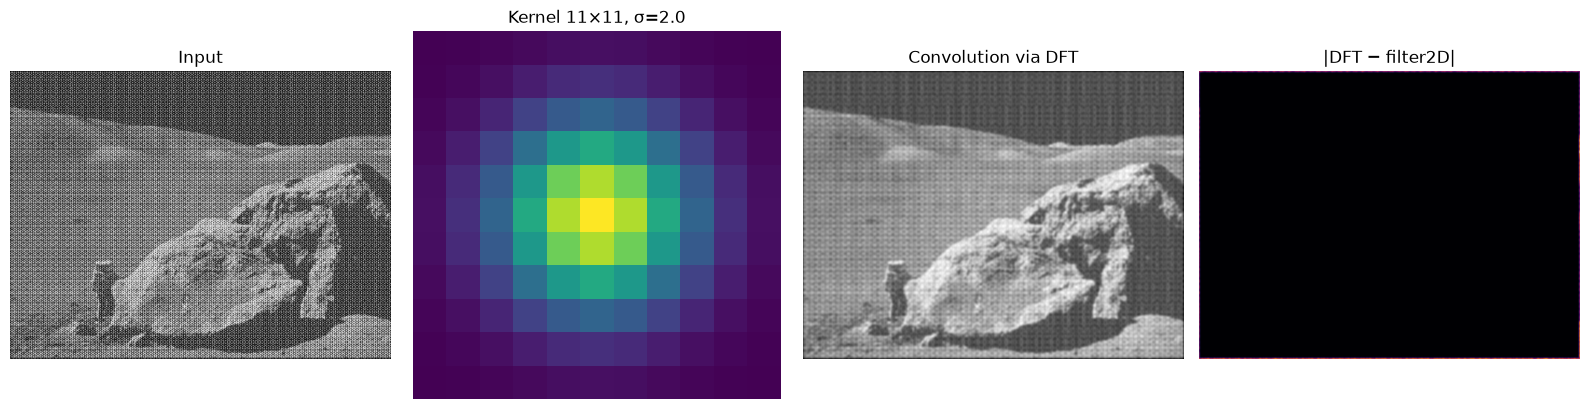

In [7]:
ksize, sigma = 11, 2.0
ax = np.arange(-(ksize // 2), ksize // 2 + 1)
xx, yy = np.meshgrid(ax, ax)
kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
kernel = (kernel / kernel.sum()).astype(np.float32)

kh, kw = kernel.shape
h, w = img.shape
H, W = h + kh - 1, w + kw - 1

img_pad = np.zeros((H, W), np.float32)
img_pad[:h, :w] = img

k_pad = np.zeros((H, W), np.float32)
k_pad[:kh, :kw] = kernel


k_pad = np.roll(k_pad, (-(kh // 2), -(kw // 2)), axis=(0, 1))

dft_img = cv.dft(img_pad, flags=cv.DFT_COMPLEX_OUTPUT)
dft_k   = cv.dft(k_pad, flags=cv.DFT_COMPLEX_OUTPUT)
prod    = cv.mulSpectrums(dft_img, dft_k, flags=0)

conv_full = cv.idft(prod, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)


conv_dft = conv_full[:h, :w]


conv_ref = cv.filter2D(np.float32(img), -1, kernel)

diff = np.abs(conv_dft - conv_ref)[ksize:-ksize, ksize:-ksize]
print(f'max diff (inner): {diff.max():.6f}')
print(f'mean diff (inner): {diff.mean():.6f}')

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(img, cmap='gray');       ax[0].set_title('Input')
ax[1].imshow(kernel, cmap='viridis'); ax[1].set_title(f'Kernel {ksize}×{ksize}, σ={sigma}')
ax[2].imshow(conv_dft, cmap='gray');  ax[2].set_title('Convolution via DFT')
ax[3].imshow(np.abs(conv_dft - conv_ref), cmap='inferno')
ax[3].set_title('|DFT − filter2D|')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

**Задание 3**

Найдено пиков-кластеров: 62
С учётом зеркальных пар: 64


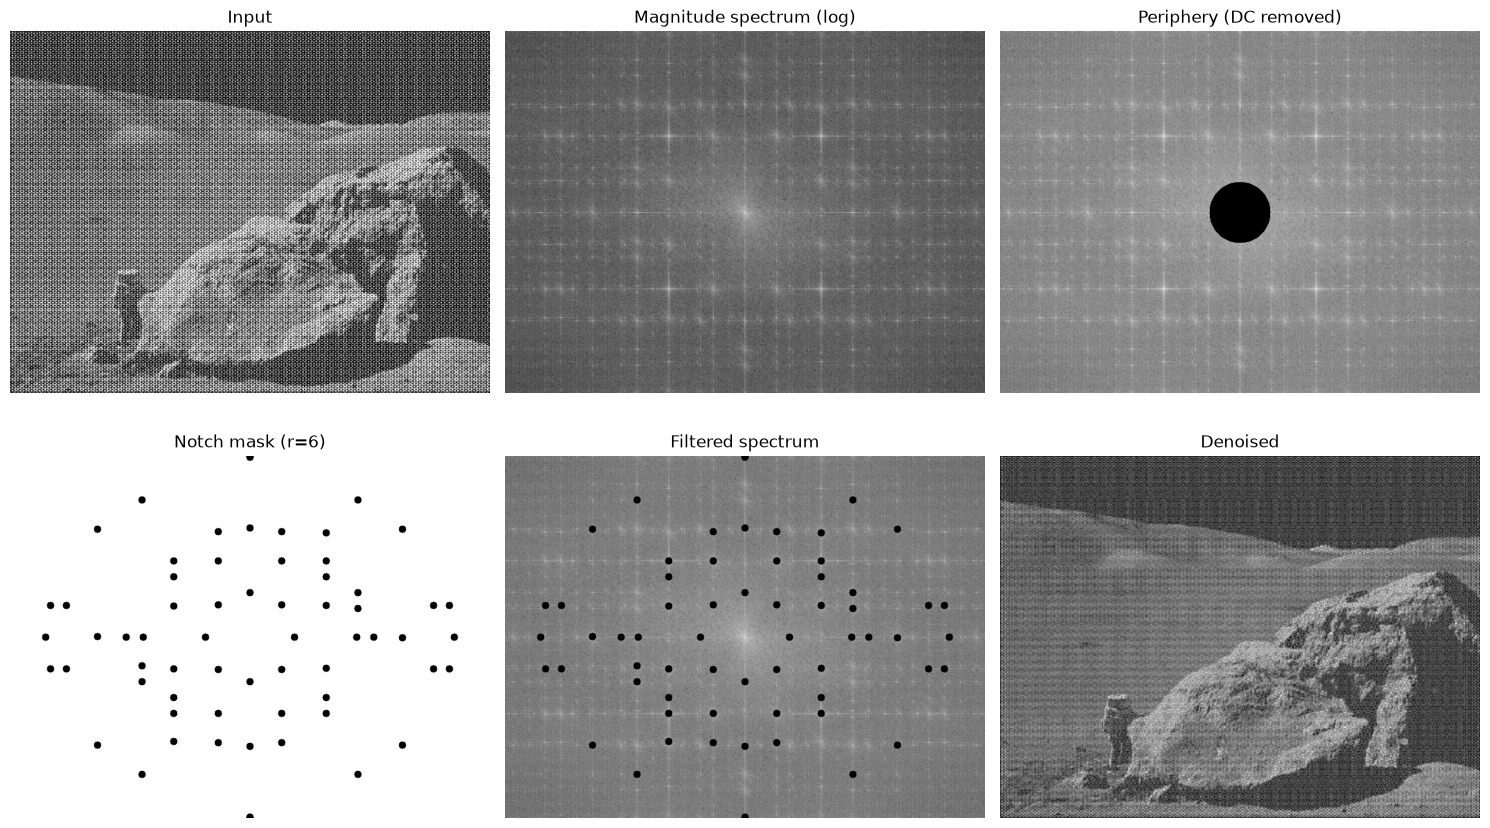

In [8]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
rows, cols = img.shape
cy, cx = rows // 2, cols // 2

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

mag = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
mag_log = 20 * np.log(mag + 1)

yy, xx = np.mgrid[0:rows, 0:cols]
dc_mask = (yy - cy)**2 + (xx - cx)**2 <= 50**2


mag_work = mag_log.copy()
mag_work[dc_mask] = 0

mag_norm = cv.normalize(mag_work, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
thr_val = np.percentile(mag_norm[mag_norm > 0], 99.9)
_, binary = cv.threshold(mag_norm, thr_val, 255, cv.THRESH_BINARY)

n_labels, labels, stats, centroids = cv.connectedComponentsWithStats(
    binary, connectivity=8
)
peaks = []
for i in range(1, n_labels):
    if stats[i, cv.CC_STAT_AREA] < 2:
        continue
    py = int(round(centroids[i][1]))
    px = int(round(centroids[i][0]))
    peaks.append((py, px))

print(f'Найдено пиков-кластеров: {len(peaks)}')


peak_set = set()
for (py, px) in peaks:
    peak_set.add((py, px))
    peak_set.add((2*cy - py, 2*cx - px))   
peaks = list(peak_set)
print(f'С учётом зеркальных пар: {len(peaks)}')

r = 6
notch_mask = np.ones((rows, cols), np.float32)
for (py, px) in peaks:
    notch_mask[(yy - py)**2 + (xx - px)**2 <= r**2] = 0.0

mask = np.dstack([notch_mask, notch_mask]).astype(np.float32)

fshift = dft_shift * mask
filtered_log = 20 * np.log(cv.magnitude(fshift[:, :, 0], fshift[:, :, 1]) + 1)

img_back = cv.idft(np.fft.ifftshift(fshift))
img_clean = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])
img_clean = cv.normalize(img_clean, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
ax[0,0].imshow(img, cmap='gray');            ax[0,0].set_title('Input')
ax[0,1].imshow(mag_log, cmap='gray');        ax[0,1].set_title('Magnitude spectrum (log)')
ax[0,2].imshow(mag_work, cmap='gray');       ax[0,2].set_title('Periphery (DC removed)')
ax[1,0].imshow(notch_mask, cmap='gray');     ax[1,0].set_title(f'Notch mask (r={r})')
ax[1,1].imshow(filtered_log, cmap='gray');   ax[1,1].set_title('Filtered spectrum')
ax[1,2].imshow(img_clean, cmap='gray');      ax[1,2].set_title('Denoised')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

max diff (inner): 0.000443
mean diff (inner): 0.000049
Найдено пиков-кластеров: 62
С учётом зеркальных пар: 64